# Hồi quy tuyến tính đa biến - OLS tự viết
Nguồn bài giảng: PDF trang 75-76 (OLS), trang 22 (fit/predict và MSE).
NumPy giải bình phương tối thiểu; không gọi sklearn LinearRegression trong mô hình chính.
Không dùng nghịch đảo (XᵀX) vì ma trận có thể suy biến. Không dùng gradient descent, learning rate hay epoch.

## 1. Công thức và mã giả
ŷ = b₀ + b₁x₁ + ... + bₚxₚ. OLS tối thiểu hóa tổng (yᵢ - ŷᵢ)² trên train.
```text
ĐẦU VÀO: X_train (N×p), y_train (N), X_new (M×p)
ĐẦU RA: dự đoán (M)
INIT(): ready ← SAI; intercept, coef ← RỖNG
BUILD_MODEL(): xóa tham số; ready ← ĐÚNG
FIT(X, y):
    NẾU chưa ready: BÁO LỖI
    KIỂM TRA kích thước và giá trị hữu hạn
    A ← GHÉP_CỘT(1, X)
    w ← GIẢI_BÌNH_PHƯƠNG_TỐI_THIỂU(A, y)
    intercept ← w[0]; coef ← w[1:]
PREDICT(X_new):
    NẾU chưa fit: BÁO LỖI
    TRẢ VỀ intercept + X_new × coef
```


## 2. Đọc ba tập đã chuẩn bị
Chạy EDA.ipynb trước. Không học lại imputer hoặc chọn đặc trưng bằng test.


In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

ROOT = Path.cwd().resolve()
while not (ROOT / "Datasets/data_raw/bigmart.csv").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Hãy mở notebook bên trong GR_05_Lab_2.")
    ROOT = ROOT.parent
processed = ROOT / "Datasets/data_processed"
output = ROOT / "outputs"
figures = output / "figures"
figures.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"
if not (processed / "preprocessing.json").is_file():
    raise FileNotFoundError("Hãy chạy EDA.ipynb từ đầu đến cuối trước.")
preprocessing = json.loads((processed / "preprocessing.json").read_text(encoding="utf-8"))
for filename, key in [("bigmart_clean.csv", "clean_sha256"), ("split_indices.csv", "split_sha256")]:
    actual = hashlib.sha256((processed / filename).read_bytes()).hexdigest()
    if actual != preprocessing[key]:
        raise ValueError("Dữ liệu đã thay đổi. Hãy chạy lại EDA.ipynb.")
splits = {}
for name in ["train", "validation", "test"]:
    X = pd.read_csv(processed / f"X_{name}.csv", index_col="source_row")
    y = pd.read_csv(processed / f"y_{name}.csv", index_col="source_row")["Item_Outlet_Sales"]
    assert X.index.equals(y.index)
    assert X.columns.tolist() == preprocessing["feature_names"]
    assert np.isfinite(X.to_numpy()).all() and y.gt(0).all()
    splits[name] = (X, y)
    print(name, "X:", X.shape, "y:", y.shape)
X_train, y_train = splits["train"]
X_validation, y_validation = splits["validation"]
X_test, y_test = splits["test"]
assert set(X_train.index).isdisjoint(X_validation.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_validation.index).isdisjoint(X_test.index)

# Lưu phiên bản để tái lập kết quả trên cùng môi trường.
import sys
import sklearn
import matplotlib
environment = {"python": sys.version.split()[0], "numpy": np.__version__,
               "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
               "matplotlib": matplotlib.__version__, "seed": 42}
(output / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")


train X: (5966, 30) y: (5966,)
validation X: (1278, 30) y: (1278,)
test X: (1279, 30) y: (1279,)


## 3. Chỉ số và baseline
MAPE bổ sung theo yêu cầu nhóm. Không chia MAPE cho số gần 0 thay thế; dữ liệu hiện tại có mục tiêu dương.


### R² - Hệ số xác định

$$R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i-\hat y_i)^2}{\sum_{i=1}^{n}(y_i-\bar y)^2}.$$

Ở đây, $\bar y$ là trung bình doanh số thật của **chính tập đang đánh giá**.
R² càng cao càng tốt: 1 là dự đoán hoàn hảo; 0 tương đương luôn dự đoán trung bình tập đánh giá;
âm là kém hơn mức đó. R² không phải Accuracy và không có đơn vị.
Ví dụ R² = 0,60 nghĩa là mô hình giải thích khoảng 60% biến thiên doanh số trên tập đó,
không phải dự đoán đúng 60% email/sản phẩm.
Baseline của lab dùng trung bình **train**, nên R² validation/test có thể âm, không bắt buộc bằng 0.
Chỉ bổ sung chỉ số đánh giá; vẫn chọn cấu hình cây theo RMSE validation, không theo R² test.


In [2]:
def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if not np.isfinite(y_pred).all():
        raise ValueError("Dự đoán chứa giá trị không hữu hạn.")
    if (y_true <= 0).any():
        raise ValueError("MAPE của bài này yêu cầu mục tiêu dương; không tự thay 0 bằng số nhỏ.")
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred),
            "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred)*100,
            "N": len(y_true), "Negative_predictions": int((y_pred < 0).sum())}

# Baseline không phải mô hình chính thứ ba: luôn dùng trung bình y_train.
baseline_mean = float(y_train.mean())
baseline_validation = np.full(len(y_validation), baseline_mean)
print("Trung bình doanh số train:", baseline_mean)
print("Baseline trên validation:", evaluate(y_validation, baseline_validation))


Trung bình doanh số train: 2204.8825196781763
Baseline trên validation: {'MAE': 1328.8729880409435, 'MSE': 2735026.1492646053, 'RMSE': np.float64(1653.79144672616), 'R2': -0.002798679925422043, 'MAPE (%)': 217.17810482500232, 'N': 1278, 'Negative_predictions': 0}


## 4. Class bốn phương thức
`build_model()` đặt lại trạng thái, `fit()` học hệ số; `predict()` dùng hệ số đã học.


In [3]:
class LinearRegressionOLS:
    def __init__(self):
        self.ready = False
        self.intercept_ = None
        self.coef_ = None

    def build_model(self):
        self.intercept_ = None
        self.coef_ = None
        self.ready = True

    def fit(self, X_train, y_train):
        if not self.ready:
            raise ValueError("Hãy gọi build_model() trước fit().")
        X = np.asarray(X_train, dtype=float)
        y = np.asarray(y_train, dtype=float)
        if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
            raise ValueError("X phải là ma trận và y là vector cùng số mẫu, không rỗng.")
        if not np.isfinite(X).all() or not np.isfinite(y).all():
            raise ValueError("Dữ liệu phải là số hữu hạn, không còn thiếu.")
        X_with_bias = np.column_stack([np.ones(len(X)), X])
        weights = np.linalg.lstsq(X_with_bias, y, rcond=None)[0]
        self.intercept_ = float(weights[0])
        self.coef_ = weights[1:]

    def predict(self, X_test):
        if self.coef_ is None:
            raise ValueError("Hãy gọi fit() trước predict().")
        X = np.asarray(X_test, dtype=float)
        if X.ndim != 2 or X.shape[1] != len(self.coef_):
            raise ValueError("Số cột đầu vào không khớp với train.")
        if not np.isfinite(X).all():
            raise ValueError("Đầu vào phải là số hữu hạn.")
        return self.intercept_ + X @ self.coef_


## 5. Fit và kiểm tra validation
OLS không có max_depth hay learning rate để tuning. Validation giúp đối chiếu với baseline và cây; không chọn biến đổi mới từ test.


In [4]:
model = LinearRegressionOLS()
model.build_model()
model.fit(X_train, y_train)
validation_prediction = model.predict(X_validation)
print("OLS validation:", evaluate(y_validation, validation_prediction))
print("OLS train:", evaluate(y_train, model.predict(X_train)))
coefficients = pd.DataFrame({"feature": X_train.columns, "coefficient": model.coef_})
coefficients.to_csv(output / "linear_regression_coefficients.csv", index=False)
print("Hệ số chặn:", model.intercept_)
print(coefficients.to_string(index=False))
print("Không diễn giải độ lớn hệ số giữa các biến khác đơn vị như độ quan trọng trực tiếp.")


OLS validation: {'MAE': 787.7647578925269, 'MSE': 1159774.6858474954, 'RMSE': np.float64(1076.9283568777894), 'R2': 0.5747680422391929, 'MAPE (%)': 99.07408326347435, 'N': 1278, 'Negative_predictions': 68}
OLS train: {'MAE': 847.5831363505921, 'MSE': 1298550.8197454603, 'RMSE': np.float64(1139.5397403098586), 'R2': 0.5609198567173816, 'MAPE (%)': 104.21436604860553, 'N': 5966, 'Negative_predictions': 288}
Hệ số chặn: -39279.971955574925
                        feature   coefficient
                    Item_Weight     -1.564731
                Item_Visibility   -430.323316
                       Item_MRP     15.814188
      Outlet_Establishment_Year     31.776660
            Item_Weight_Missing -12471.443078
            Outlet_Size_Missing   -185.944349
           Item_Visibility_Zero     48.633409
       Item_Fat_Content_Regular     76.036225
               Item_Type_Breads    -15.519847
            Item_Type_Breakfast     30.840690
               Item_Type_Canned     28.473802
       

## 6. Đánh giá cuối trên test
Giữ dự đoán âm nếu có và ghi số lượng; không cắt ngầm về 0 để cải thiện chỉ số.


In [5]:
MODEL_TITLE = "Linear Regression OLS"
MODEL_PREFIX = "linear_regression"
PARAMETERS = {"method": "numpy.linalg.lstsq", "fit_intercept": True}

# Chỉ chạy phần này sau khi phương pháp/cấu hình đã chốt bằng validation.
# Giữ mô hình đã fit trên train, không fit lại trên train+validation trong báo cáo này.
test_prediction = model.predict(X_test)
baseline_test = np.full(len(y_test), baseline_mean)
rows = []
for split, truth, prediction in [
    ("train", y_train, model.predict(X_train)),
    ("validation", y_validation, model.predict(X_validation)),
    ("test", y_test, test_prediction),
]:
    rows.append({"Model": MODEL_TITLE, "Split": split, **evaluate(truth, prediction)})
metrics = pd.DataFrame(rows)
baseline_rows = []
for split, truth in [("train", y_train), ("validation", y_validation), ("test", y_test)]:
    baseline_rows.append({"Model": "Baseline mean", "Split": split,
                          **evaluate(truth, np.full(len(truth), baseline_mean))})
baseline_metrics = pd.DataFrame(baseline_rows)
metrics.to_csv(output / f"{MODEL_PREFIX}_metrics.csv", index=False)
baseline_metrics.to_csv(output / "baseline_metrics.csv", index=False)

predictions = pd.DataFrame({"source_row": y_test.index, "actual": y_test.to_numpy(),
                            "prediction": test_prediction, "baseline_prediction": baseline_test})
predictions["residual"] = predictions["actual"] - predictions["prediction"]
predictions["absolute_error"] = predictions["residual"].abs()
predictions["APE (%)"] = predictions["absolute_error"] / predictions["actual"]*100
predictions.to_csv(output / f"{MODEL_PREFIX}_predictions.csv", index=False)
predictions.nlargest(20, "absolute_error").to_csv(output / f"{MODEL_PREFIX}_largest_errors.csv", index=False)
run_info = {"model": MODEL_TITLE, "preprocessing_sha256": hashlib.sha256((processed / "preprocessing.json").read_bytes()).hexdigest(),
            "selection_metric": "validation RMSE", "test_used_for_tuning": False,
            "parameters": PARAMETERS, "negative_prediction_policy": "Giữ nguyên, không cắt về 0 để làm đẹp điểm."}
(output / f"{MODEL_PREFIX}_run.json").write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8")
print(metrics.round(4).to_string(index=False))
print("Baseline test:")
print(baseline_metrics.loc[baseline_metrics["Split"] == "test"].round(4).to_string(index=False))
print("Số dự đoán test âm:", int((test_prediction < 0).sum()))
print("MSE có đơn vị bình phương; MAPE là %, MAE/RMSE cùng đơn vị với mục tiêu.")


                Model      Split      MAE          MSE      RMSE     R2  MAPE (%)    N  Negative_predictions
Linear Regression OLS      train 847.5831 1298550.8197 1139.5397 0.5609  104.2144 5966                   288
Linear Regression OLS validation 787.7648 1159774.6858 1076.9284 0.5748   99.0741 1278                    68
Linear Regression OLS       test 833.1474 1260792.4704 1122.8502 0.5614  115.5457 1279                    78
Baseline test:
        Model Split       MAE          MSE      RMSE      R2  MAPE (%)    N  Negative_predictions
Baseline mean  test 1347.8084 2879273.7084 1696.8423 -0.0017  249.8494 1279                     0
Số dự đoán test âm: 78
MSE có đơn vị bình phương; MAPE là %, MAE/RMSE cùng đơn vị với mục tiêu.


## 7. Trực quan hóa và phân tích sai số
MAPE nhạy với doanh số nhỏ. Hai mô hình dùng cùng test, không kết luận mô hình luôn tốt trên mọi dữ liệu.


5 mẫu có sai số tuyệt đối lớn nhất:
 source_row   actual  prediction  baseline_prediction  residual  absolute_error  APE (%)
       1450 11445.10     5559.09              2204.88   5886.01         5886.01    51.43
        997  9275.93     4179.80              2204.88   5096.13         5096.13    54.94
       7256  8323.83     3304.06              2204.88   5019.77         5019.77    60.31
       1009 10236.67     5275.05              2204.88   4961.63         4961.63    48.47
       3154  8912.40     4475.95              2204.88   4436.45         4436.45    49.78
Sai số lớn nhất không tự chứng minh nhãn sai; cần tra source_row trong dữ liệu gốc.


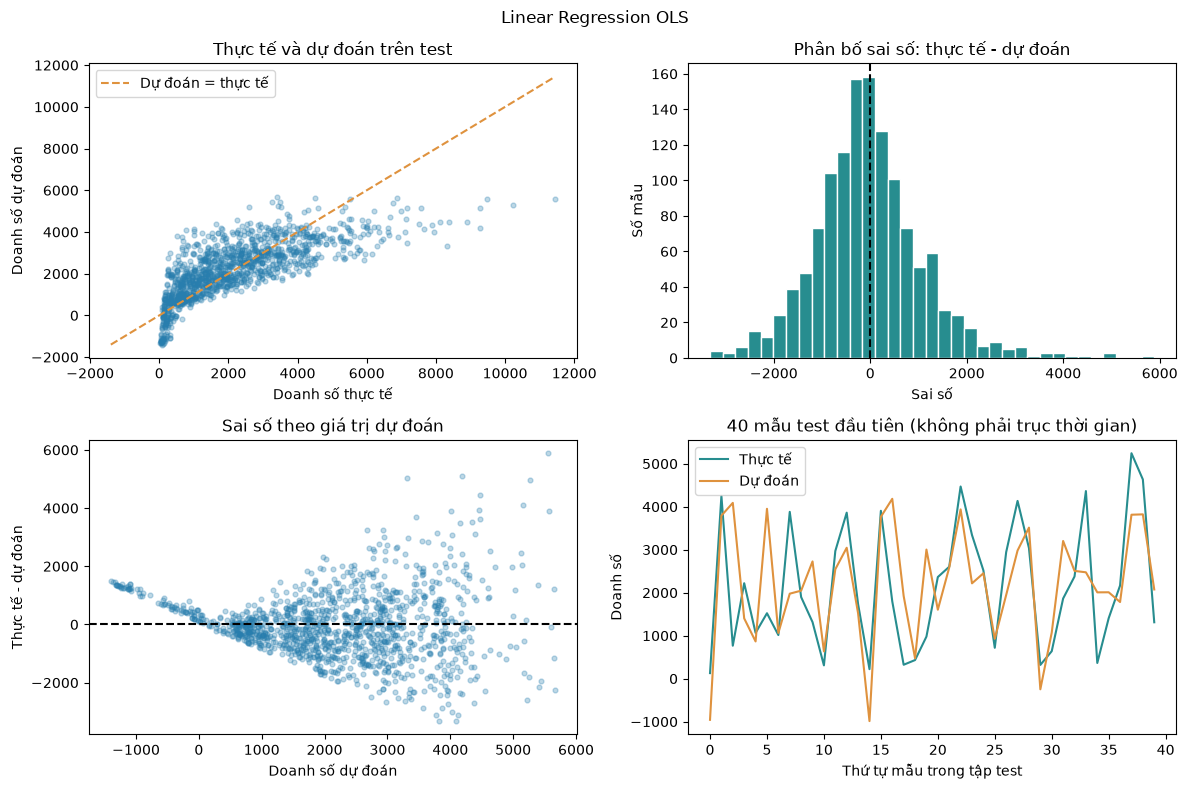

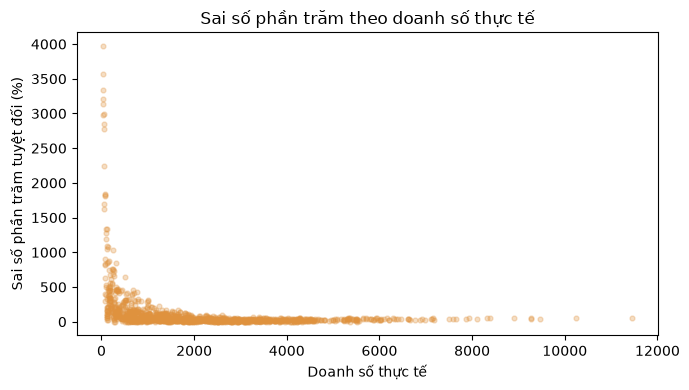

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
lower = min(float(y_test.min()), float(np.min(test_prediction)))
upper = max(float(y_test.max()), float(np.max(test_prediction)))
axes[0, 0].scatter(y_test, test_prediction, s=12, alpha=0.3, color="#287eae")
axes[0, 0].plot([lower, upper], [lower, upper], color="#df923e", linestyle="--", label="Dự đoán = thực tế")
axes[0, 0].set_title("Thực tế và dự đoán trên test")
axes[0, 0].set_xlabel("Doanh số thực tế")
axes[0, 0].set_ylabel("Doanh số dự đoán")
axes[0, 0].legend()
axes[0, 1].hist(predictions["residual"], bins=35, color="#278d8f", edgecolor="white")
axes[0, 1].axvline(0, color="black", linestyle="--")
axes[0, 1].set_title("Phân bố sai số: thực tế - dự đoán")
axes[0, 1].set_xlabel("Sai số")
axes[0, 1].set_ylabel("Số mẫu")
axes[1, 0].scatter(test_prediction, predictions["residual"], s=12, alpha=0.3, color="#287eae")
axes[1, 0].axhline(0, color="black", linestyle="--")
axes[1, 0].set_title("Sai số theo giá trị dự đoán")
axes[1, 0].set_xlabel("Doanh số dự đoán")
axes[1, 0].set_ylabel("Thực tế - dự đoán")
sample = predictions.head(40)
axes[1, 1].plot(range(len(sample)), sample["actual"], label="Thực tế", color="#278d8f")
axes[1, 1].plot(range(len(sample)), sample["prediction"], label="Dự đoán", color="#df923e")
axes[1, 1].set_title("40 mẫu test đầu tiên (không phải trục thời gian)")
axes[1, 1].set_xlabel("Thứ tự mẫu trong tập test")
axes[1, 1].set_ylabel("Doanh số")
axes[1, 1].legend()
fig.suptitle(MODEL_TITLE)
fig.tight_layout()
fig.savefig(figures / f"{MODEL_PREFIX}_evaluation.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(y_test, predictions["APE (%)"], s=12, alpha=0.3, color="#df923e")
ax.set_title("Sai số phần trăm theo doanh số thực tế")
ax.set_xlabel("Doanh số thực tế")
ax.set_ylabel("Sai số phần trăm tuyệt đối (%)")
fig.tight_layout()
fig.savefig(figures / f"{MODEL_PREFIX}_percentage_errors.png", dpi=180, bbox_inches="tight")
plt.show()

print("5 mẫu có sai số tuyệt đối lớn nhất:")
print(predictions.nlargest(5, "absolute_error").round(2).to_string(index=False))
print("Sai số lớn nhất không tự chứng minh nhãn sai; cần tra source_row trong dữ liệu gốc.")


In [ ]:
# Các khoảng cố định chỉ dùng phân tích lỗi sau đánh giá, không thay cấu hình.
error_groups = predictions.copy()
error_groups["Actual_sales_group"] = pd.cut(
    error_groups["actual"], bins=[0, 500, 1000, 3000, np.inf],
    labels=["(0, 500]", "(500, 1000]", "(1000, 3000]", "> 3000"])
error_by_sales = error_groups.groupby("Actual_sales_group", observed=True).agg(
    N=("actual", "size"), MAE=("absolute_error", "mean"), MAPE_percent=("APE (%)", "mean"))
error_by_sales.to_csv(output / f"{MODEL_PREFIX}_errors_by_sales.csv")
print(error_by_sales.round(2).to_string())


                      N      MAE  MAPE_percent
Actual_sales_group                            
(0, 500]            193   732.32        499.06
(500, 1000]         201   715.23        102.72
(1000, 3000]        552   682.65         40.53
> 3000              333  1212.23         25.36
MAPE là trung bình tỷ lệ sai số theo từng mẫu; có thể vượt 100%, không phải accuracy.
Mục tiêu nhỏ có thể tạo sai số phần trăm lớn dù sai số tuyệt đối chưa lớn nhất.


## 8. Demo sản phẩm mới
Dùng thống kê và danh mục đã lưu từ train. Đầu vào mẫu không thuộc phần đánh giá.


In [8]:
# Hai đầu vào giả định để minh họa API, không dùng tính điểm test.
new_products = pd.DataFrame([
    {"Item_Weight": 9.3, "Item_Visibility": 0.02, "Item_MRP": 150.0,
     "Outlet_Establishment_Year": 1999, "Item_Fat_Content": "Low Fat", "Item_Type": "Dairy",
     "Outlet_Size": "Medium", "Outlet_Location_Type": "Tier 1", "Outlet_Type": "Supermarket Type1"},
    {"Item_Weight": np.nan, "Item_Visibility": 0.04, "Item_MRP": 80.0,
     "Outlet_Establishment_Year": 2000, "Item_Fat_Content": "Regular", "Item_Type": "Soft Drinks",
     "Outlet_Size": None, "Outlet_Location_Type": "Tier 3", "Outlet_Type": "Grocery Store"},
])
demo = new_products.copy()
demo["Item_Weight_Missing"] = demo["Item_Weight"].isna().astype(int)
demo["Outlet_Size_Missing"] = demo["Outlet_Size"].isna().astype(int)
demo["Item_Visibility_Zero"] = demo["Item_Visibility"].eq(0).astype(int)
demo["Item_Weight"] = demo["Item_Weight"].fillna(preprocessing["weight_median"])
demo["Outlet_Size"] = demo["Outlet_Size"].fillna(preprocessing["size_mode"])
# Tái sử dụng danh mục đã học từ train; không học lại từ sản phẩm demo.
for column in preprocessing["category_columns"]:
    categories = preprocessing["categories"][column]
    if not demo[column].isin(categories).all():
        raise ValueError("Danh mục demo chưa gặp ở train: " + column)
    demo[column] = pd.Categorical(demo[column], categories=categories)
demo_encoded = pd.get_dummies(demo[preprocessing["category_columns"]], drop_first=True, dtype=float)
demo_X = pd.concat([demo[preprocessing["numeric_columns"]].astype(float), demo_encoded], axis=1)
demo_X = demo_X.reindex(columns=preprocessing["feature_names"], fill_value=0.0)
assert np.isfinite(demo_X.to_numpy()).all()
new_products["Predicted_Item_Outlet_Sales"] = model.predict(demo_X)
print(new_products.to_string(index=False))


 Item_Weight  Item_Visibility  Item_MRP  Outlet_Establishment_Year Item_Fat_Content   Item_Type Outlet_Size Outlet_Location_Type       Outlet_Type  Predicted_Item_Outlet_Sales
         9.3             0.02     150.0                       1999          Low Fat       Dairy      Medium               Tier 1 Supermarket Type1                  2413.681508
         NaN             0.04      80.0                       2000          Regular Soft Drinks         NaN               Tier 3     Grocery Store                -13007.303947


## 9. Nhận xét cần đọc cùng kết quả
- So sánh RMSE/MAE với baseline để biết mô hình có học được thông tin hữu ích.
- OLS mô tả quan hệ tuyến tính; có thể bỏ sót tương tác và dự đoán âm.
- Các cột danh mục có phụ thuộc có thể làm hệ số không duy nhất; least-squares chọn một nghiệm, không dùng để khẳng định quan hệ nhân quả.
- Mở Decision_Tree.ipynb tiếp theo để so sánh cùng tập test.
